<a href="https://colab.research.google.com/github/Ram-Paliwal/Handwritten-Character-Recognition/blob/main/Handwritten_Character_Recognition_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# Handwritten Character Recognition
# Objective: Identify handwritten characters or alphabets.
# Approach: Use image processing and deep learning.
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow import keras
from tensorflow.keras import layers

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score
)

import seaborn as sns

# Check TensorFlow version
print("TensorFlow Version:", tf.__version__)

# Check GPU availability
print("GPU Available:", tf.config.list_physical_devices('GPU'))

print("\nLibraries imported successfully!")

TensorFlow Version: 2.21.0
GPU Available: []

Libraries imported successfully!


In [2]:

# Install EMNIST dataset package

!pip -q install emnist


In [7]:

import os
import gzip
import struct
import urllib.request
import numpy as np

# Dataset download location
os.makedirs("/content/emnist_data", exist_ok=True)

BASE_URL = (
    "https://huggingface.co/datasets/"
    "Heliosoph/EMNIST/resolve/main/"
)

files = {
    "train_images": "emnist-balanced-train-images-idx3-ubyte.gz",
    "train_labels": "emnist-balanced-train-labels-idx1-ubyte.gz",
    "test_images": "emnist-balanced-test-images-idx3-ubyte.gz",
    "test_labels": "emnist-balanced-test-labels-idx1-ubyte.gz"
}

# Download files
for key, filename in files.items():

    path = f"/content/emnist_data/{filename}"

    if not os.path.exists(path):
        print("Downloading:", filename)

        urllib.request.urlretrieve(
            BASE_URL + filename,
            path
        )

    print("Ready:", filename)


# Read image IDX file
def load_images(path):

    with gzip.open(path, 'rb') as f:

        magic, count, rows, cols = struct.unpack(
            ">IIII", f.read(16)
        )

        assert magic == 2051, "Invalid image file!"

        data = np.frombuffer(
            f.read(), dtype=np.uint8
        )

    return data.reshape(count, rows, cols)


# Read label IDX file
def load_labels(path):

    with gzip.open(path, 'rb') as f:

        magic, count = struct.unpack(
            ">II", f.read(8)
        )

        assert magic == 2049, "Invalid label file!"

        data = np.frombuffer(
            f.read(), dtype=np.uint8
        )

    return data


# Load training and testing data
X_train = load_images(
    "/content/emnist_data/" + files["train_images"]
)

y_train = load_labels(
    "/content/emnist_data/" + files["train_labels"]
)

X_test = load_images(
    "/content/emnist_data/" + files["test_images"]
)

y_test = load_labels(
    "/content/emnist_data/" + files["test_labels"]
)

print("\n========== DATASET LOADED ==========")

print("Training Images:", X_train.shape)
print("Training Labels:", y_train.shape)

print("Testing Images:", X_test.shape)
print("Testing Labels:", y_test.shape)

print("Number of Classes:", len(np.unique(y_train)))

assert X_train.shape == (112800, 28, 28)
assert X_test.shape == (18800, 28, 28)

print("\nEMNIST BALANCED LOADED SUCCESSFULLY!")


Downloading: emnist-balanced-train-images-idx3-ubyte.gz
Ready: emnist-balanced-train-images-idx3-ubyte.gz
Downloading: emnist-balanced-train-labels-idx1-ubyte.gz
Ready: emnist-balanced-train-labels-idx1-ubyte.gz
Downloading: emnist-balanced-test-images-idx3-ubyte.gz
Ready: emnist-balanced-test-images-idx3-ubyte.gz
Downloading: emnist-balanced-test-labels-idx1-ubyte.gz
Ready: emnist-balanced-test-labels-idx1-ubyte.gz

========== DATASET LOADED ==========
Training Images: (112800, 28, 28)
Training Labels: (112800,)
Testing Images: (18800, 28, 28)
Testing Labels: (18800,)
Number of Classes: 47

EMNIST BALANCED LOADED SUCCESSFULLY!


In [8]:

class_names = list("0123456789ABCDEFGHIJKLMNOPQRSTUVWXYZabdefghnqrt")

print("Total Classes:", len(class_names))

for i, character in enumerate(class_names):
    print(f"Label {i:2d} = {character}")

assert len(class_names) == 47


Total Classes: 47
Label  0 = 0
Label  1 = 1
Label  2 = 2
Label  3 = 3
Label  4 = 4
Label  5 = 5
Label  6 = 6
Label  7 = 7
Label  8 = 8
Label  9 = 9
Label 10 = A
Label 11 = B
Label 12 = C
Label 13 = D
Label 14 = E
Label 15 = F
Label 16 = G
Label 17 = H
Label 18 = I
Label 19 = J
Label 20 = K
Label 21 = L
Label 22 = M
Label 23 = N
Label 24 = O
Label 25 = P
Label 26 = Q
Label 27 = R
Label 28 = S
Label 29 = T
Label 30 = U
Label 31 = V
Label 32 = W
Label 33 = X
Label 34 = Y
Label 35 = Z
Label 36 = a
Label 37 = b
Label 38 = d
Label 39 = e
Label 40 = f
Label 41 = g
Label 42 = h
Label 43 = n
Label 44 = q
Label 45 = r
Label 46 = t


In [9]:

# Correct EMNIST orientation
X_train = np.transpose(X_train, (0, 2, 1))
X_test = np.transpose(X_test, (0, 2, 1))

# Normalize pixel values
X_train = X_train.astype("float32") / 255.0
X_test = X_test.astype("float32") / 255.0

# Add channel dimension
X_train = X_train[..., np.newaxis]
X_test = X_test[..., np.newaxis]

print("Training:", X_train.shape)
print("Testing:", X_test.shape)

print("Pixel range:", X_train.min(), "-", X_train.max())


Training: (112800, 28, 28, 1)
Testing: (18800, 28, 28, 1)
Pixel range: 0.0 - 1.0


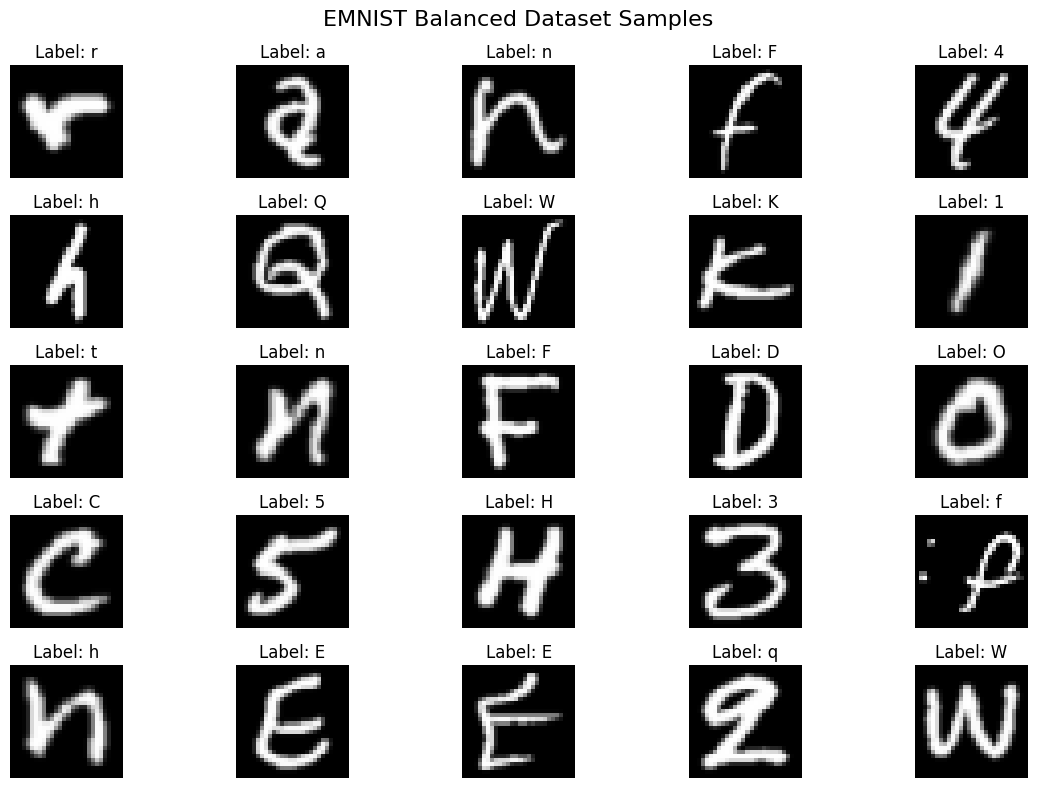

In [10]:

plt.figure(figsize=(12, 8))

for i in range(25):
    plt.subplot(5, 5, i + 1)

    plt.imshow(X_train[i].squeeze(), cmap='gray')
    plt.title(f"Label: {class_names[y_train[i]]}")
    plt.axis('off')

plt.suptitle("EMNIST Balanced Dataset Samples", fontsize=16)
plt.tight_layout()
plt.show()


In [11]:

from sklearn.model_selection import train_test_split

SEED = 42

indices = np.arange(len(X_train))

train_idx, val_idx = train_test_split(
    indices,
    test_size=0.20,
    random_state=SEED,
    stratify=y_train
)

X_val = X_train[val_idx]
y_val = y_train[val_idx]

X_train = X_train[train_idx]
y_train = y_train[train_idx]

print("Training samples:", len(X_train))
print("Validation samples:", len(X_val))
print("Testing samples:", len(X_test))


Training samples: 90240
Validation samples: 22560
Testing samples: 18800


In [12]:

from tensorflow import keras
from tensorflow.keras import layers

# Build CNN architecture

model = keras.Sequential([

    layers.Input(shape=(28, 28, 1)),

    # Block 1
    layers.Conv2D(32, (3, 3), padding='same'),
    layers.BatchNormalization(),
    layers.Activation('relu'),
    layers.MaxPooling2D((2, 2)),

    # Block 2
    layers.Conv2D(64, (3, 3), padding='same'),
    layers.BatchNormalization(),
    layers.Activation('relu'),
    layers.MaxPooling2D((2, 2)),

    # Block 3
    layers.Conv2D(128, (3, 3), padding='same'),
    layers.BatchNormalization(),
    layers.Activation('relu'),

    # Classification
    layers.GlobalAveragePooling2D(),
    layers.Dropout(0.4),

    layers.Dense(128, activation='relu'),
    layers.Dropout(0.3),

    layers.Dense(47, activation='softmax')
])

# Compile model
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 28, 28, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 28, 28, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 28, 28, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 14, 14, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 14, 14, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 7, 7, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 7, 7, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 7, 7, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 47)             │         6,063 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 116,143 (453.68 KB)

 Trainable params: 115,695 (451.93 KB)

 Non-trainable params: 448 (1.75 KB)

In [13]:

callbacks = [

    keras.callbacks.EarlyStopping(
        monitor='val_loss',
        patience=4,
        restore_best_weights=True
    ),

    keras.callbacks.ReduceLROnPlateau(
        monitor='val_loss',
        factor=0.5,
        patience=2,
        min_lr=0.00001
    ),

    keras.callbacks.ModelCheckpoint(
        'best_emnist_model.keras',
        monitor='val_accuracy',
        save_best_only=True
    )
]

history = model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=20,
    batch_size=128,
    callbacks=callbacks,
    verbose=1
)


Epoch 1/20
705/705 ━━━━━━━━━━━━━━━━━━━━ 114s 159ms/step - accuracy: 0.4421 - loss: 1.8894 - val_accuracy: 0.5995 - val_loss: 1.2291 - learning_rate: 0.0010
Epoch 2/20
705/705 ━━━━━━━━━━━━━━━━━━━━ 137s 152ms/step - accuracy: 0.6963 - loss: 0.9441 - val_accuracy: 0.7835 - val_loss: 0.6454 - learning_rate: 0.0010
Epoch 3/20
705/705 ━━━━━━━━━━━━━━━━━━━━ 141s 150ms/step - accuracy: 0.7489 - loss: 0.7689 - val_accuracy: 0.8174 - val_loss: 0.5471 - learning_rate: 0.0010
Epoch 4/20
705/705 ━━━━━━━━━━━━━━━━━━━━ 145s 154ms/step - accuracy: 0.7724 - loss: 0.6844 - val_accuracy: 0.8133 - val_loss: 0.5585 - learning_rate: 0.0010
Epoch 5/20
705/705 ━━━━━━━━━━━━━━━━━━━━ 137s 147ms/step - accuracy: 0.7894 - loss: 0.6340 - val_accuracy: 0.8249 - val_loss: 0.5172 - learning_rate: 0.0010
Epoch 6/20
705/705 ━━━━━━━━━━━━━━━━━━━━ 104s 148ms/step - accuracy: 0.8011 - loss: 0.5950 - val_accuracy: 0.8307 - val_loss: 0.4926 - learning_rate: 0.0010
Epoch 7/20
705/705 ━━━━━━━━━━━━━━━━━━━━ 143s 150ms/step - accura

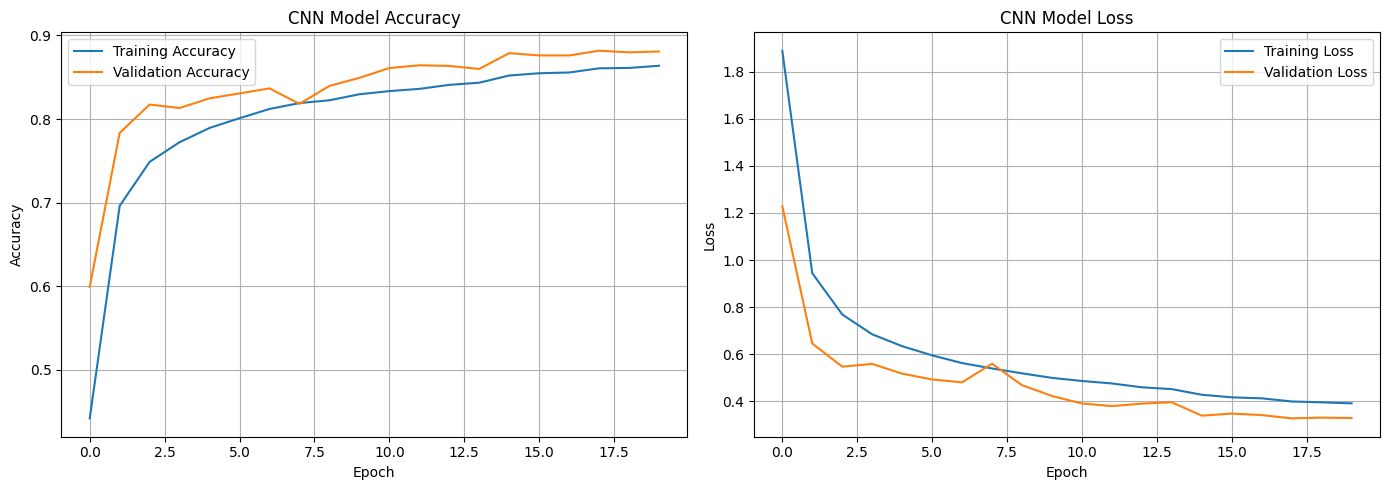

In [14]:

plt.figure(figsize=(14, 5))

# Accuracy
plt.subplot(1, 2, 1)

plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')

plt.title('CNN Model Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)

# Loss
plt.subplot(1, 2, 2)

plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')

plt.title('CNN Model Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()


In [15]:

test_loss, test_accuracy = model.evaluate(
    X_test,
    y_test,
    verbose=1
)

print("\n========== FINAL TEST RESULTS ==========")

print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy * 100:.2f}%")


588/588 ━━━━━━━━━━━━━━━━━━━━ 7s 11ms/step - accuracy: 0.8792 - loss: 0.3426

========== FINAL TEST RESULTS ==========
Test Loss: 0.3426
Test Accuracy: 87.92%


In [16]:

from sklearn.metrics import classification_report, accuracy_score

y_pred_prob = model.predict(
    X_test,
    batch_size=256,
    verbose=1
)

y_pred = np.argmax(y_pred_prob, axis=1)

print("Test Accuracy:", accuracy_score(y_test, y_pred))

print("\nClassification Report:\n")

print(classification_report(
    y_test,
    y_pred,
    labels=np.arange(47),
    target_names=class_names,
    zero_division=0
))


74/74 ━━━━━━━━━━━━━━━━━━━━ 6s 79ms/step
Test Accuracy: 0.8792021276595745

Classification Report:

              precision    recall  f1-score   support

           0       0.65      0.70      0.68       400
           1       0.51      0.77      0.61       400
           2       0.90      0.89      0.89       400
           3       0.99      0.99      0.99       400
           4       0.94      0.89      0.91       400
           5       0.96      0.89      0.92       400
           6       0.94      0.95      0.95       400
           7       0.97      0.99      0.98       400
           8       0.91      0.96      0.94       400
           9       0.62      0.91      0.74       400
           A       0.96      0.98      0.97       400
           B       0.97      0.96      0.97       400
           C       0.96      0.96      0.96       400
           D       0.93      0.91      0.92       400
           E       0.98      0.98      0.98       400
           F       0.72      0.47   

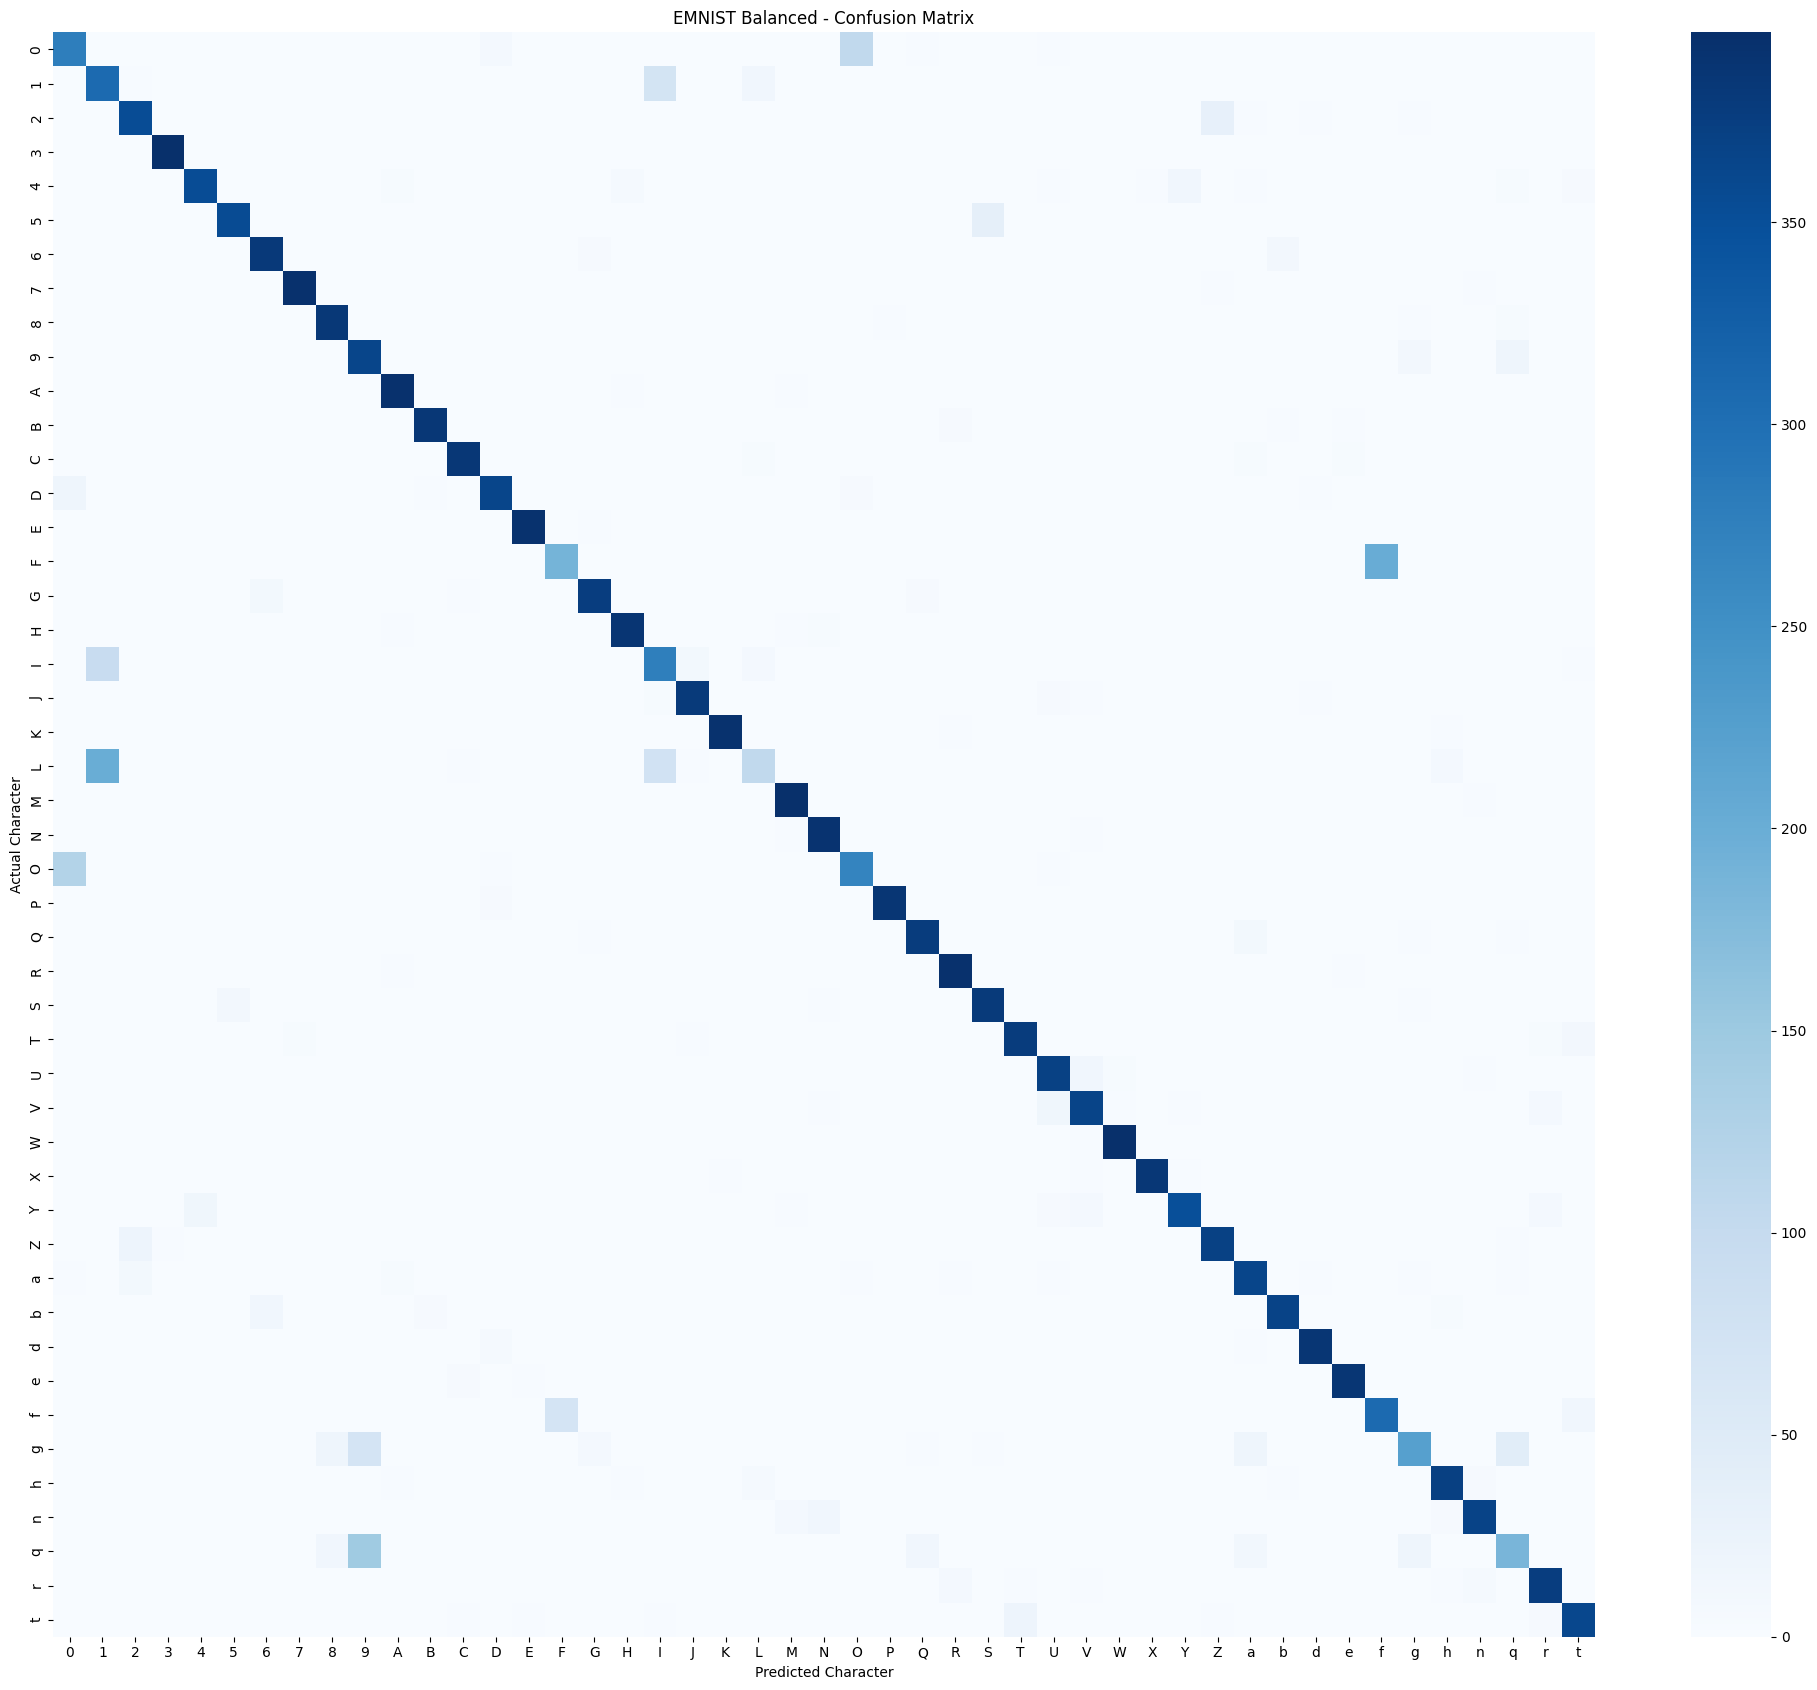

In [17]:

from sklearn.metrics import confusion_matrix

cm = confusion_matrix(
    y_test,
    y_pred,
    labels=np.arange(47)
)

plt.figure(figsize=(20, 17))

sns.heatmap(
    cm,
    cmap='Blues',
    xticklabels=class_names,
    yticklabels=class_names,
    annot=False
)

plt.title("EMNIST Balanced - Confusion Matrix")
plt.xlabel("Predicted Character")
plt.ylabel("Actual Character")

plt.tight_layout()
plt.show()


In [18]:

# ============================================
# FINAL TEST EVALUATION
# ============================================

test_loss, test_accuracy = model.evaluate(
    X_test,
    y_test,
    verbose=1
)

print("\n========== FINAL RESULTS ==========")

print(f"Test Accuracy: {test_accuracy * 100:.2f}%")
print(f"Test Loss: {test_loss:.4f}")


588/588 ━━━━━━━━━━━━━━━━━━━━ 7s 12ms/step - accuracy: 0.8792 - loss: 0.3426

========== FINAL RESULTS ==========
Test Accuracy: 87.92%
Test Loss: 0.3426


In [26]:

def preprocess_custom_image(image_bytes):

    image = Image.open(BytesIO(image_bytes)).convert("L")
    image = np.array(image)

    # Determine background using corner pixels
    corners = [
        image[0, 0], image[0, -1],
        image[-1, 0], image[-1, -1]
    ]

    background = np.mean(corners)

    # Ensure white character on black background
    if background > 127:
        image = 255 - image

    # Threshold
    _, binary = cv2.threshold(
        image, 0, 255,
        cv2.THRESH_BINARY + cv2.THRESH_OTSU
    )

    # Remove small noise
    kernel = np.ones((2, 2), np.uint8)
    binary = cv2.morphologyEx(
        binary, cv2.MORPH_OPEN, kernel
    )

    # Find character boundaries
    coords = cv2.findNonZero(binary)

    if coords is None:
        raise ValueError("No character detected!")

    x, y, w, h = cv2.boundingRect(coords)
    character = binary[y:y+h, x:x+w]

    # Resize preserving aspect ratio
    scale = 20 / max(w, h)

    nw = max(1, int(w * scale))
    nh = max(1, int(h * scale))

    character = cv2.resize(
        character,
        (nw, nh),
        interpolation=cv2.INTER_AREA
    )

    # Center on 28x28 canvas
    canvas = np.zeros((28, 28), dtype=np.uint8)

    xoff = (28 - nw) // 2
    yoff = (28 - nh) // 2

    canvas[yoff:yoff+nh, xoff:xoff+nw] = character

    # Normalize
    return (canvas.astype("float32") / 255.0).reshape(1, 28, 28, 1)


Saving Screenshot 2026-11-02 233750.png to Screenshot 2026-11-02 233750.png


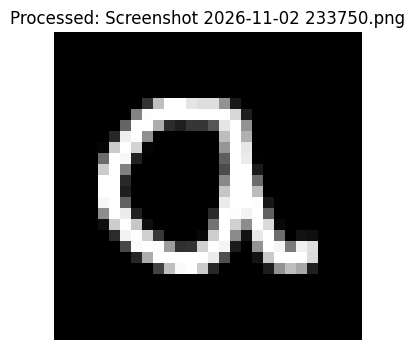


File: Screenshot 2026-11-02 233750.png
Predicted: a

TOP 5 PREDICTIONS:
a: 96.17%
q: 2.34%
Q: 0.71%
g: 0.66%
U: 0.03%

Input pixel sum: 111.67
--------------------------------


In [31]:

from google.colab import files

uploaded = files.upload()

for filename, content in uploaded.items():

    processed_image = preprocess_custom_image(content)

    prediction = model.predict(
        processed_image,
        verbose=0
    )[0]

    top_indices = np.argsort(prediction)[-5:][::-1]

    # Display processed image
    plt.figure(figsize=(4, 4))
    plt.imshow(
        processed_image[0].squeeze(),
        cmap="gray",
        interpolation="nearest"
    )
    plt.title("Processed: " + filename)
    plt.axis("off")
    plt.show()

    print("\nFile:", filename)
    print("Predicted:", class_names[np.argmax(prediction)])

    print("\nTOP 5 PREDICTIONS:")

    for idx in top_indices:
        print(
            f"{class_names[idx]}: "
            f"{prediction[idx]*100:.2f}%"
        )

    print("\nInput pixel sum:",
          round(float(processed_image.sum()), 2))

    print("--------------------------------")


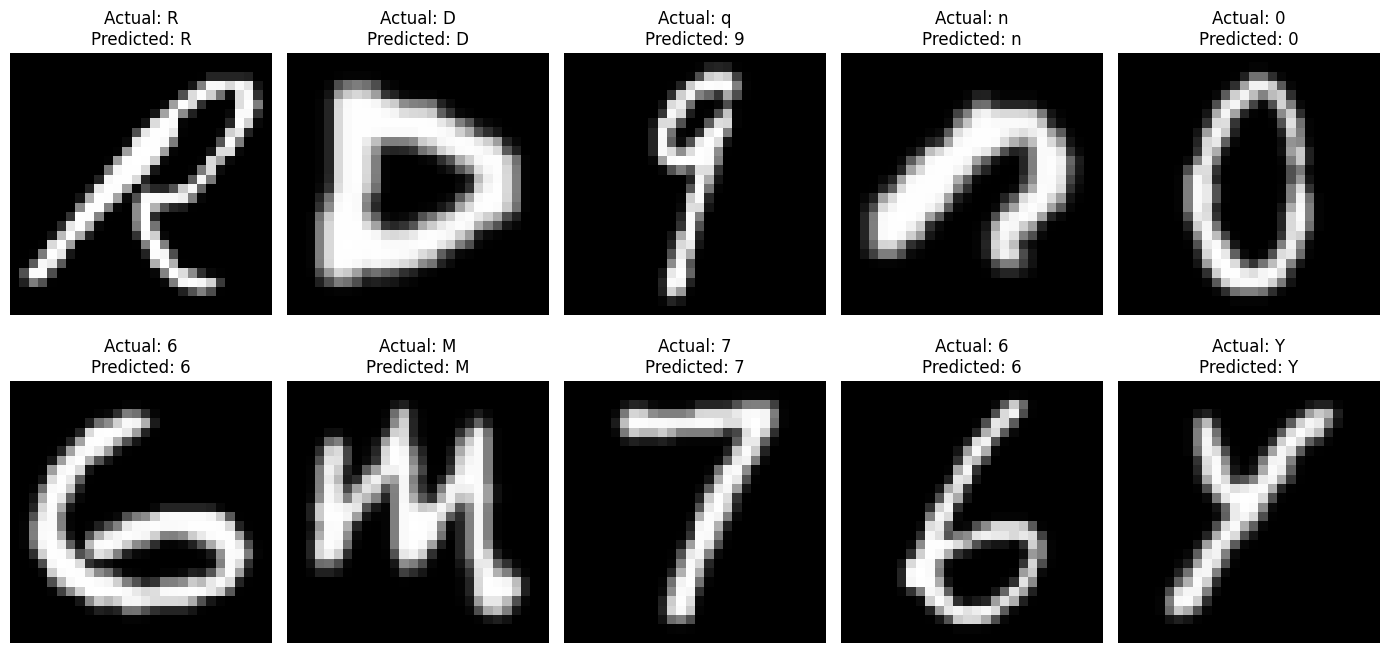

In [30]:

# Test model on 10 different official test images

sample_indices = np.random.choice(
    len(X_test), 10, replace=False
)

plt.figure(figsize=(14, 7))

for i, idx in enumerate(sample_indices):

    image = X_test[idx:idx+1]

    pred = model.predict(image, verbose=0)

    predicted = np.argmax(pred)
    actual = y_test[idx]

    plt.subplot(2, 5, i+1)

    plt.imshow(image[0].squeeze(), cmap="gray")

    plt.title(
        f"Actual: {class_names[actual]}\n"
        f"Predicted: {class_names[predicted]}"
    )

    plt.axis("off")

plt.tight_layout()
plt.show()
